# Dual Axis vs. Indexed Line

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

A dual-axis chart plots two measures with different units against two independent y-scales. Because the designer picks both scales, where the lines cross, how steep they look, and whether they seem to move together are all arbitrary. The chart can invent a correlation, or hide one.

## When to use

- Use an indexed line chart (each series = 100 at a common start) to compare the growth of measures with different units
- Use two stacked charts with a shared x-axis when the absolute levels matter

## Avoid when

- Two measures with different units or scales that you want to show "together"
- Revenue vs. users, price vs. volume, cases vs. tests

## Alternatives

- Indexed line chart (rebased to 100)
- Two aligned panels sharing the x-axis (small multiples)
- Connected scatter plot (one measure on each axis)

## Design tips

- Rebase each series to 100 at a meaningful start date and label the axis "Index (start = 100)"
- Label line ends directly instead of using a legend
- If absolute values matter, put them in the tooltip, table or subtitle

## Example

Monthly active users (thousands) and revenue ($M) of an app over three years.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(21)
months = pd.date_range("2022-01", periods=36, freq="MS")
users_k = 10 * np.exp(np.linspace(0, np.log(3.0), 36)) * (1 + rng.normal(0, 0.02, 36))
revenue_m = 2.0 * np.exp(np.linspace(0, np.log(1.7), 36)) * (1 + rng.normal(0, 0.02, 36))
df = pd.DataFrame({"month": months, "users_k": users_k, "revenue_m": revenue_m})
df.head()

,month,users_k,revenue_m
0,2022-01-01,10.071755,2.015775
1,2022-02-01,10.630637,2.003126
2,2022-03-01,10.267489,2.071399
3,2022-04-01,11.358061,2.067734
4,2022-05-01,11.327054,2.133063


### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_55524/3827857309.py:20: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax3.text(df["month"].iloc[-1] + pd.Timedelta(days=20), idx[col].iloc[-1],
/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_55524/3827857309.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax3.set_xlim(df["month"].iloc[0], df["month"].iloc[-1] + pd.Timedelta(days=200))


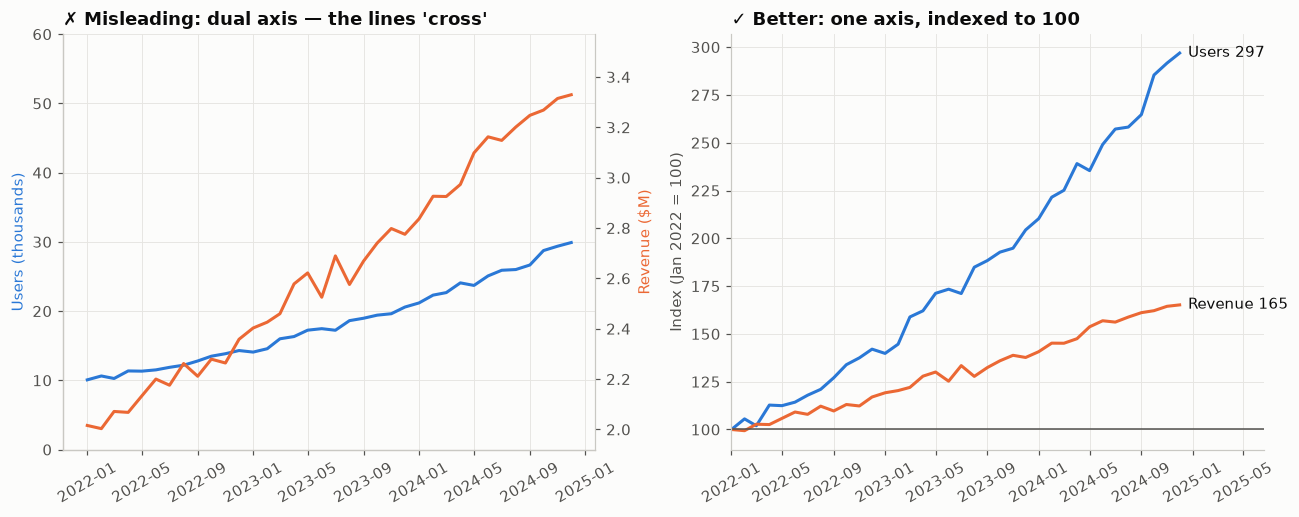

In [3]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4.8))

# Misleading: two independent y-scales, chosen so the lines cross.
ax1.plot(df["month"], df["users_k"], color=PALETTE[0], label="Users (k)")
ax1.set_ylabel("Users (thousands)", color=PALETTE[0])
ax1.set_ylim(0, 60)
ax2 = ax1.twinx()
ax2.plot(df["month"], df["revenue_m"], color=PALETTE[1], label="Revenue ($M)")
ax2.set_ylabel("Revenue ($M)", color=PALETTE[1])
ax2.set_ylim(1.92, 3.57)
ax2.spines["right"].set_visible(True)
ax2.grid(False)
ax1.set_title("✗ Misleading: dual axis — the lines 'cross'", fontsize=11.5)
ax1.tick_params(axis="x", rotation=30)

# Better: one honest axis, both series indexed to 100 at the start.
idx = df[["users_k", "revenue_m"]] / df[["users_k", "revenue_m"]].iloc[0] * 100
for col, color, name in [("users_k", PALETTE[0], "Users"), ("revenue_m", PALETTE[1], "Revenue")]:
    ax3.plot(df["month"], idx[col], color=color)
    ax3.text(df["month"].iloc[-1] + pd.Timedelta(days=20), idx[col].iloc[-1],
             f"{name} {idx[col].iloc[-1]:.0f}", color="#0b0b0b", va="center", fontsize=9.5)
ax3.axhline(100, color="#52514e", linewidth=1)
ax3.set_ylabel("Index (Jan 2022 = 100)")
ax3.set_xlim(df["month"].iloc[0], df["month"].iloc[-1] + pd.Timedelta(days=200))
ax3.set_title("✓ Better: one axis, indexed to 100", fontsize=11.5)
ax3.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## How to read it

On the left, revenue starts below users, shoots past them in late 2022 and ends far above, which looks like revenue grew much faster. Both the crossing and the slopes come only from the two chosen axis ranges. On the right, both series start at 100: users actually grew about 3× and revenue only about 1.65×, which is the opposite story.

---
Standalone script: [`dual_axis_vs_indexed.py`](dual_axis_vs_indexed.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)